# Toy problem: RV-SDDP versus mean-scenario initializations

On the toy problem of `notebook_toy.ipynb`, we compare RV-SDDP with two cheap ways of using the **mean scenario** to help cyclic SDDP with the large level, of order $1/(1-\beta)$, of the value function.

Let $\bar V$ be the value function of the deterministic problem where the inflow is replaced by its mean $\bar\omega = \mathbb{E}[\omega]$. The stage problem is a linear program with $\omega$ in the right-hand side, hence jointly convex in $(x, \omega)$, and Jensen's inequality gives $T(V) \geq \bar T(V)$ for every convex $V$. By induction $\bar V \leq V^*$, so $\bar V$ is a valid set of initial cuts. Two techniques follow:

1. **Warm start**: start cyclic SDDP or RV-SDDP from $\bar V$ instead of $0$.
2. **Constant shift**: start from $0$ and run RV-SDDP with the constant shift $\Delta = (1-\beta)\min_x \bar V(x)$ instead of the random shift. This is the shift that turns $\min \bar V$ into the stationary level of the shifted fixed point $V = T(V) - \Delta$.

Five methods are therefore compared, each for `n_iterations` iterations. $\bar V$ itself is obtained by `n_iterations_mean` iterations of cyclic SDDP on the mean problem.

| Method | Initial value function | Shift |
|---|---|---|
| Cyclic SDDP | $0$ | none |
| RV-SDDP | $0$ | random |
| Cyclic SDDP + $\bar V$ | $\bar V$ | none |
| RV-SDDP + $\bar V$ | $\bar V$ | random |
| Constant shift | $0$ | $\Delta = (1-\beta)\min \bar V$ |

In [60]:
import Pkg
Pkg.activate(".")

  Activating project at `~/Documents/RVSDDP`


In [61]:
using RVSDDP
using Random
using Plots
using Statistics
using Gurobi
const GRB_ENV = Gurobi.Env()
Gurobi.GRBsetintparam(GRB_ENV, "Threads", 1)  # un seul thread, comme dans les scripts run_*.jl
optimizer=() -> Gurobi.Optimizer(GRB_ENV)
using LaTeXStrings

Set parameter Username
Set parameter LicenseID to value 2818369
Academic license - for non-commercial use only - expires 2027-05-05
Set parameter Threads to value 1


## The toy problem

In [62]:
discount_factor = 0.99
period = 1
graph = RVSDDP.InfiniteLinearGraph(period);
n_iterations = 70       # iterations of each of the five methods
n_iterations_mean = 100  # iterations of cyclic SDDP on the mean problem

100

In [63]:
function subproblem_builder(subproblem::Model, node::Int, discount_factor::Float64; Ω = [20.0, 90.0])
    # State variables
    @variable(subproblem, 0 <= volume <= 200, RVSDDP.State, initial_value = 50)
    # Control variables
    @variables(subproblem, begin
        thermal_generation >= 0
        hydro_generation >= 0
        hydro_spill >= 0
        deficit >= 0
    end)
    # Random variables
    @variable(subproblem, inflow)
    P = [1 / length(Ω) for _ in Ω]
    RVSDDP.parameterize(subproblem, Ω, P) do ω
        return JuMP.fix(inflow, ω)
    end

    # Transition function and constraints
    @constraints(
        subproblem,
        begin
            volume.out == volume.in - hydro_generation - hydro_spill + inflow
            hydro_generation <= 100
            thermal_generation <= 30
            deficit + hydro_generation + thermal_generation == 60
        end
    )
    # Stage-objective
    @stageobjective(subproblem, 50*hydro_spill + 50 * deficit+ 2*thermal_generation)
    return subproblem
end

# Le meme probleme, avec l'apport remplace par sa moyenne.
mean_subproblem_builder(subproblem::Model, node::Int, discount_factor::Float64) =
    subproblem_builder(subproblem, node, discount_factor; Ω = [(20.0 + 90.0) / 2])

mean_subproblem_builder (generic function with 1 method)

## The five methods

* The cuts of $\bar V$ are copied before training as ordinary cuts with shift $0$, through the same routine `train` uses for its own cuts, so that every replica of the subproblem gets them too. The random shift only ever lowers the shift of a cut, so they are never moved.
* The constant shift is a shift rule, in the sense of `src/core/shifts.jl`, that returns $\Delta$ at every step. Each new cut is stored at its intercept minus $\Delta$, and no existing cut is moved.
* After each iteration, the Bellman residual $T(V)(x) - V(x)$ is evaluated on a grid of the state box by a `post_iteration_callback`. It consumes no randomness, so the training trajectories are the same as without it. Its **span** $\max_x - \min_x$ is the convergence criterion that is common to all methods: it goes to $0$ for cyclic SDDP, whose residual goes to $0$, as well as for the shifted methods, whose residual goes to a constant.

In [64]:
function add_mean_scenario_cuts!(model)
    # Avec period = 1, le noeud 1 porte sa propre fonction de cout futur.
    node = model[1]
    child = model[node.children[1].term]
    for c in mean_model[1].value_function.cut_V[2:end]  # cut_V[1] est la borne inferieure
        cut = RVSDDP.CandidateCut(0, 0.0, c.intercept, copy(c.coefficients), copy(c.state))
        RVSDDP._add_cut_constraint_to_model(
            model,
            node,
            node.bellman_function.global_theta,
            cut,
            (0.0, RVSDDP.next_cut_index(child)),
        )
    end
    return model
end

constant_shift(Δ) = (model, node, batch_items, trial_states, candidates) -> (Δ, RVSDDP.next_cut_index(node))

residual_grid = 0.0:5.0:200.0
bellman_residuals(model) = [
    RVSDDP.compute_TV(model[1], Dict(:volume => x)) - RVSDDP.compute_V(model[1].value_function, Dict(:volume => x))
    for x in residual_grid
]

function run_method(shift_function, iterations; warm_start = false, seed = 1, builder = subproblem_builder)
    model = RVSDDP.PolicyGraph(
        builder,
        graph;
        sense = :Min,
        lower_bound = 0.0,
        optimizer = optimizer,
        discount_factor = discount_factor,
    )
    warm_start && add_mean_scenario_cuts!(model)
    residuals = Vector{Float64}[]
    Random.seed!(seed)
    RVSDDP.train(model; refine_scheme = RVSDDP.refine_all, parallel = 1, sampling_scheme = RVSDDP.InSampleMonteCarlo(rollout_limit = i -> period*i), iteration_limit = iterations, infinite = true, shift_function = shift_function, post_iteration_callback = result -> push!(residuals, bellman_residuals(model)))
    return (model = model, residuals = residuals)
end

run_method (generic function with 2 methods)

## Mean-scenario value function $\bar V$

$\bar V$ is computed by the package itself on the same problem with the inflow replaced by its mean $\bar\omega = 55$ (`mean_subproblem_builder`), with **cyclic SDDP for `n_iterations_mean` iterations**. Without shift, its cuts stay below the value function of the mean problem, hence below $V^*$ by Jensen, so they are valid initial cuts for the stochastic problem.

In [65]:
mean_model = run_method(RVSDDP.no_shift, n_iterations_mean; builder = mean_subproblem_builder).model
V_mean(x) = RVSDDP.compute_V(mean_model[1].value_function, Dict(:volume => x))

min_V_mean = minimum(V_mean(x) for x in 0.0:0.5:200.0)
Δ_const = (1 - discount_factor) * min_V_mean
println("Number of cuts of V̄: ", RVSDDP.count_cuts(mean_model[1]))
println("min V̄ = ", round(min_V_mean; digits = 2), ",  Δ = (1-β) min V̄ = ", round(Δ_const; digits = 3))

Number of cuts of V̄: 5050
min V̄ = 630.33,  Δ = (1-β) min V̄ = 6.303


In [66]:
# Couleur : regle de shift. Trait : initialisation (pointilles = depart de V̄).
variants = [
    (name = "Cyclic SDDP", label = "Cyclic SDDP", shift = RVSDDP.no_shift, warm_start = false, color = 1, style = :solid),
    (name = "RV-SDDP", label = "RV-SDDP", shift = RVSDDP.random_shift, warm_start = false, color = 2, style = :solid),
    (name = L"Cyclic SDDP $+\ \bar{V}$", label = "Cyclic SDDP + V̄", shift = RVSDDP.no_shift, warm_start = true, color = 1, style = :dash),
    (name = L"RV-SDDP $+\ \bar{V}$", label = "RV-SDDP + V̄", shift = RVSDDP.random_shift, warm_start = true, color = 2, style = :dash),
    (name = "Constant shift", label = "Constant shift", shift = constant_shift(Δ_const), warm_start = false, color = 3, style = :dot),
];

In [67]:
runs = [run_method(m.shift, n_iterations; warm_start = m.warm_start) for m in variants];

## Convergence: span of the Bellman residual

Left: span of $T(V) - V$ on the grid after each iteration. Right: its minimum, i.e. the level the residual settles at. RV-SDDP selects its shift as a minimum of residuals, so its minimum residual estimates the shift it ends up using; the constant shift $\Delta$ is drawn for comparison.

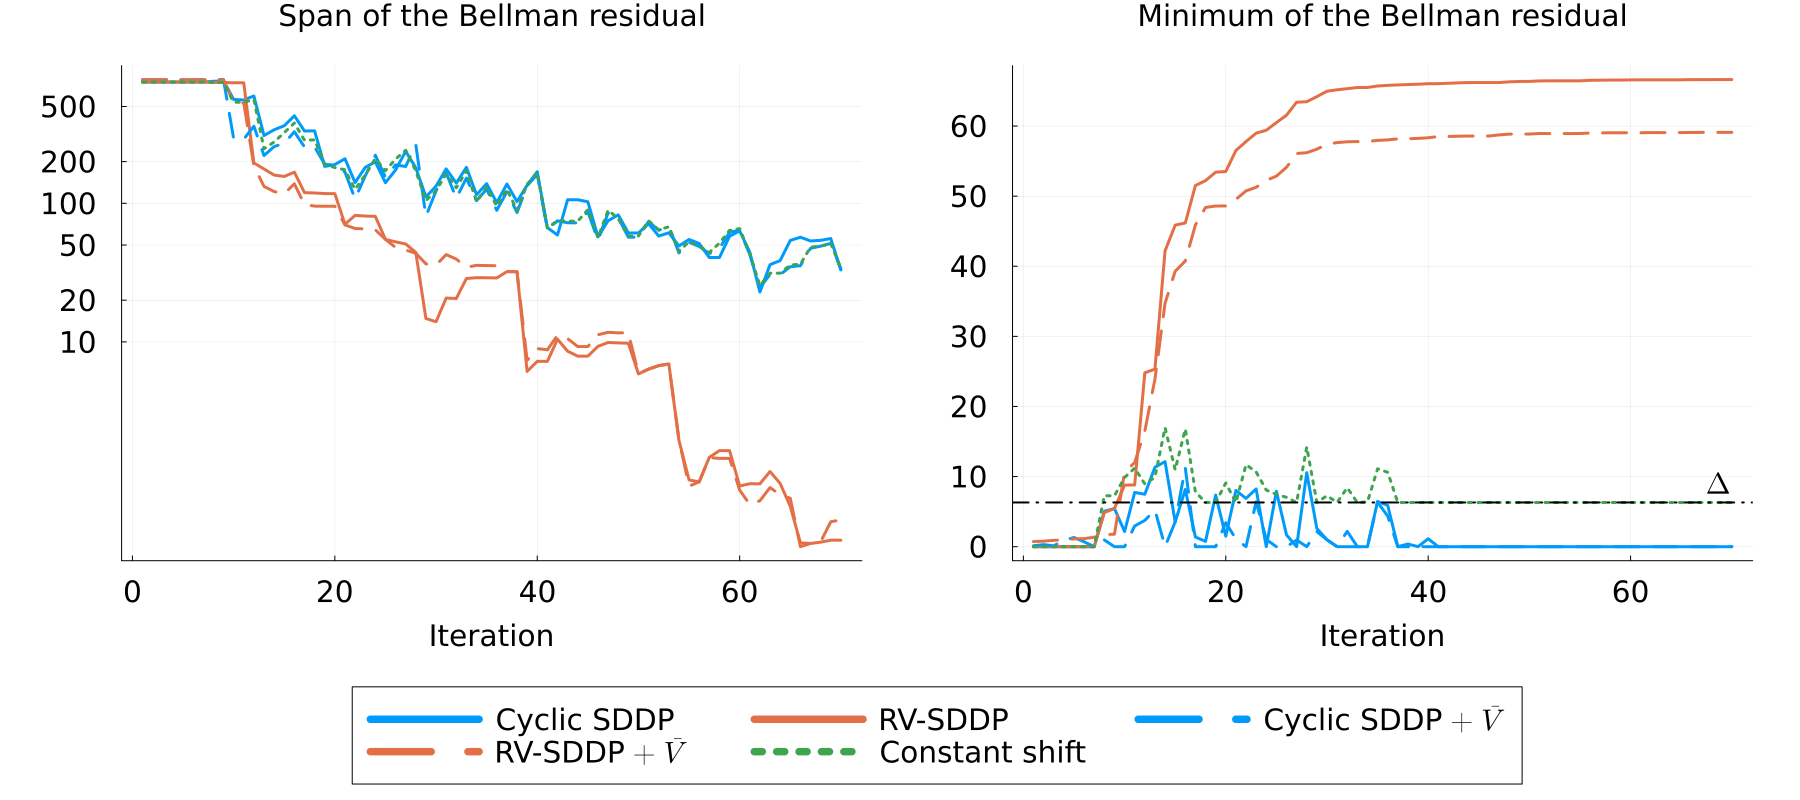

In [68]:
fontsize = 20
span(residuals) = maximum(residuals) - minimum(residuals)

p1 = plot(xlabel = "Iteration", yscale = :log10, yticks = ([10, 20, 50, 100, 200, 500], ["10", "20", "50", "100", "200", "500"]), guidefontsize = fontsize, tickfontsize = fontsize, titlefontsize = fontsize, margin = 10Plots.mm, title = "Span of the Bellman residual")
p2 = plot(xlabel = "Iteration", guidefontsize = fontsize, tickfontsize = fontsize, titlefontsize = fontsize, margin = 10Plots.mm, title = "Minimum of the Bellman residual")
for (m, result) in zip(variants, runs)
    plot!(p1, 1:n_iterations, [max(span(residuals), 1e-2) for residuals in result.residuals], label = false, linewidth = 3, color = m.color, linestyle = m.style)
    plot!(p2, 1:n_iterations, [minimum(residuals) for residuals in result.residuals], label = false, linewidth = 3, color = m.color, linestyle = m.style)
end
hline!(p2, [Δ_const], label = false, linewidth = 2, color = :black, linestyle = :dashdot)
annotate!(p2, n_iterations, Δ_const, text(L"\Delta", fontsize, :right, :bottom))

pleg = plot(framestyle = :none, legend = :bottom, legend_columns = 3, legendfontsize = fontsize, ticks = false, grid = false)
for m in variants
    plot!(pleg, [NaN], [NaN], label = m.name, linewidth = 3, color = m.color, linestyle = m.style)
end

plot(p1, p2, pleg, layout = @layout([a b; c{0.2h}]), size = (1800, 800))

In [69]:
checkpoints = round.(Int, range(n_iterations / 3, n_iterations; length = 3))
println(rpad("Span at iteration", 20), join(lpad(k, 10) for k in checkpoints))
for (m, result) in zip(variants, runs)
    println(rpad(m.label, 20), join(lpad(round(span(result.residuals[k]); digits = 1), 10) for k in checkpoints))
end

Span at iteration           23        47        70
Cyclic SDDP              181.6      74.9      33.0
RV-SDDP                   80.9       9.9       0.4
Cyclic SDDP + V̄          157.5      85.3      33.7
RV-SDDP + V̄               65.3      11.7       0.5
Constant shift           160.0      89.2      33.8


## Final value functions

The value functions and Bellman residuals at the end of training. Left: $V$ itself, with $\bar V$ in black. The shifted methods only learn $V$ up to an additive constant, so their level is not comparable with $V^*$; the middle panel removes it by plotting $V(x) - V(x_0)$, with $x_0 = 50$ the initial volume. Right: Bellman residual $T(V) - V$, whose flatness is what matters for the policy.

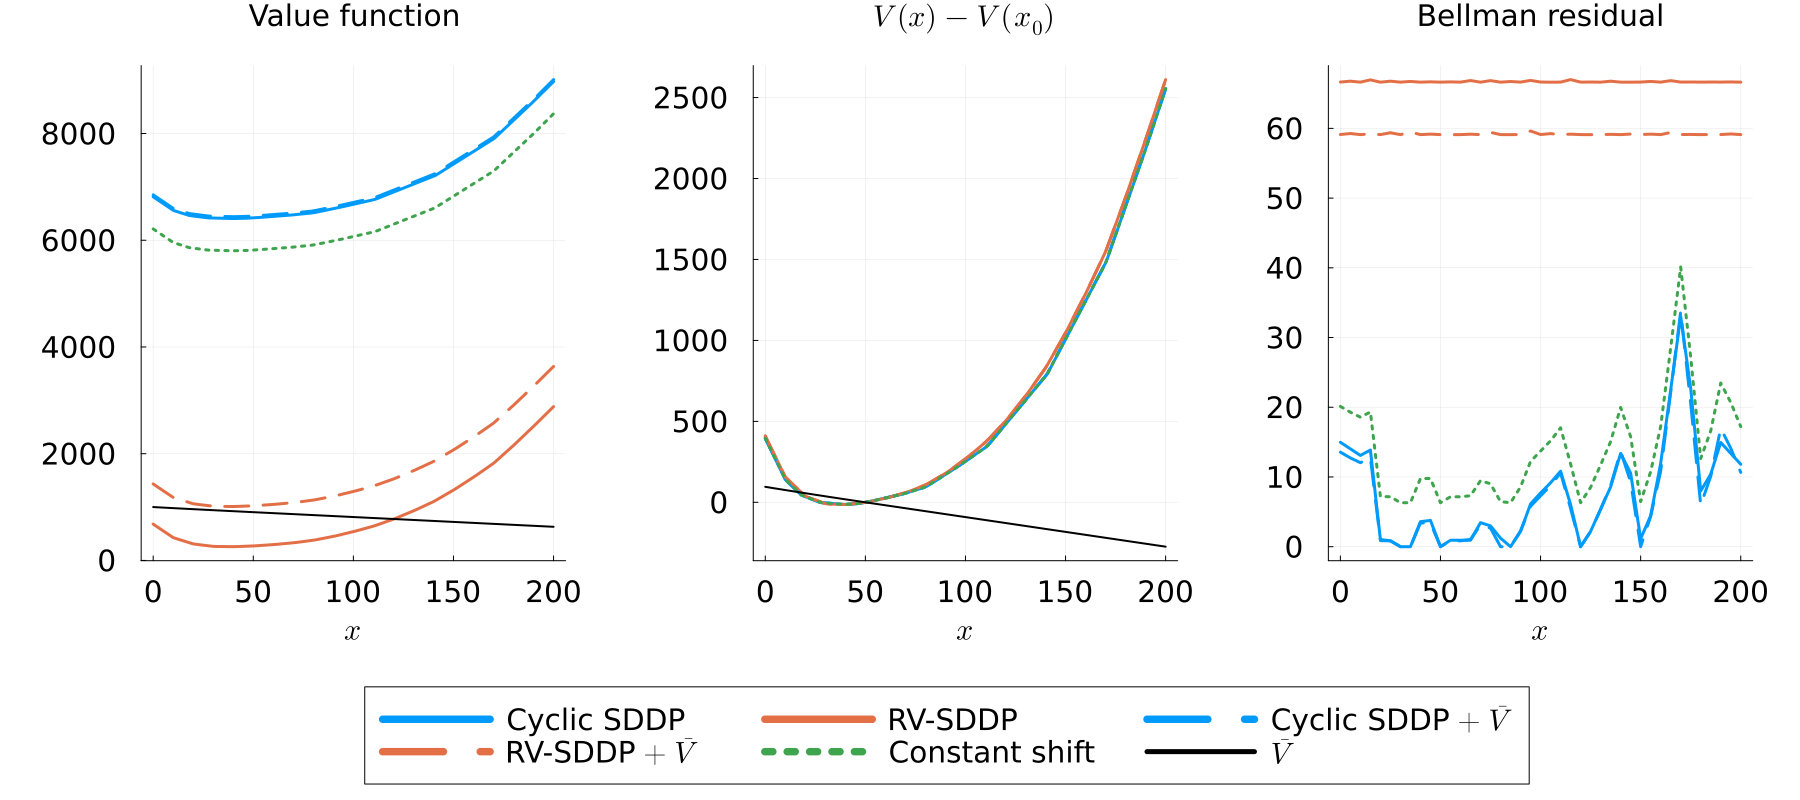

In [70]:
ind = 0.0:1.0:200.0
x0 = 50.0
V_at(model, x) = RVSDDP.compute_V(model[1].value_function, Dict(:volume => x))

p1 = plot(xlabel = L"x", guidefontsize = fontsize, tickfontsize = fontsize, titlefontsize = fontsize, margin = 10Plots.mm, title = "Value function")
p2 = plot(xlabel = L"x", guidefontsize = fontsize, tickfontsize = fontsize, titlefontsize = fontsize, margin = 10Plots.mm, title = L"V(x) - V(x_0)")
p3 = plot(xlabel = L"x", guidefontsize = fontsize, tickfontsize = fontsize, titlefontsize = fontsize, margin = 10Plots.mm, title = "Bellman residual")
for (m, result) in zip(variants, runs)
    V = [V_at(result.model, x) for x in ind]
    plot!(p1, ind, V, label = false, linewidth = 3, color = m.color, linestyle = m.style)
    plot!(p2, ind, V .- V_at(result.model, x0), label = false, linewidth = 3, color = m.color, linestyle = m.style)
    plot!(p3, residual_grid, result.residuals[end], label = false, linewidth = 3, color = m.color, linestyle = m.style)
end
plot!(p1, ind, V_mean.(ind), label = false, linewidth = 2, color = :black)
plot!(p2, ind, V_mean.(ind) .- V_mean(x0), label = false, linewidth = 2, color = :black)

pleg = plot(framestyle = :none, legend = :bottom, legend_columns = 3, legendfontsize = fontsize, ticks = false, grid = false)
for m in variants
    plot!(pleg, [NaN], [NaN], label = m.name, linewidth = 3, color = m.color, linestyle = m.style)
end
plot!(pleg, [NaN], [NaN], label = L"\bar{V}", linewidth = 2, color = :black)

plot(p1, p2, p3, pleg, layout = @layout([a b c; d{0.2h}]), size = (1800, 800))

## Observations

With `n_iterations = n_iterations_mean = 30`:

* **The mean scenario gets the level of $V^*$ badly wrong.** $\min \bar V \approx 602$, while the minimum residual RV-SDDP settles at (about 65 after 30 iterations) indicates a level of order $65/(1-\beta) \approx 6500$. The cost of this problem comes from the inflow variability (spillage when the reservoir is full, deficit when it is empty), which the mean scenario removes. $\Delta \approx 6.0$ is therefore about ten times too small.
* **It also gets the shape wrong.** $\bar V$ is decreasing and almost linear, whereas $V^*$ is U-shaped, because a full reservoir exposes it to spillage (middle panel). After 30 iterations, the warm-started value functions are above $\bar V$ everywhere, so none of its cuts is still active (left panel).
* **Warm start.** Starting from $\bar V$ helps cyclic SDDP only marginally (span 111 against 133 after 30 iterations). For RV-SDDP, it lowers the span from iteration 12 on, and ends at 12 against 14. The gap stays small next to the gap between the shifted and unshifted methods, and these are single runs (seed 1).
* **Constant shift.** It tracks cyclic SDDP almost exactly. This is expected: with a constant shift, each iteration is the cyclic SDDP iteration for the stage cost $c - \Delta$. Its fixed point is $V^* - \min \bar V \geq 0$, which it approaches from below as cyclic SDDP does, so the level still to be learned is $\min V^* - \min \bar V$, of the same order as for cyclic SDDP. Its residual levels off around $\Delta$ instead of $0$, but its span decreases at the speed of cyclic SDDP. Over 30 iterations it does not get any closer to convergence than cyclic SDDP.